# Numerical simulation 3: wind mixing of a stratified lake

**37EFM Environmental Fluid Mechanics, TU/e**

The same lake as in the convection exercise (`efmgotm/cases/lake.yaml`), now stirred by a wind stress at the surface. The turbulence produced by the shear near the surface works against the stratification and deepens a mixed layer. The sheet gives the scaling

$$h \sim u_* \sqrt{t / N}, \qquad u_* = \sqrt{\tau_x / \rho_0}.$$

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import efmgotm
from efmgotm import analysis
plt.rcParams['figure.dpi'] = 80
RUNS = 'runs'          # run directories are created here

## (a) Stratification and wind

$N^2 = 10^{-4}$ s$^{-2}$ and three wind stresses. The three runs are kept in a dictionary.

In [2]:
N2 = 1e-4
stresses = [1e-4, 1e-3, 1e-2]
runs = {}
for tau in stresses:
    runs[tau] = efmgotm.run('lake', {'temperature.NN': N2, 'surface.fluxes.heat.constant_value': 0.0,
                                     'surface.fluxes.tx.constant_value': tau}, workdir=RUNS)

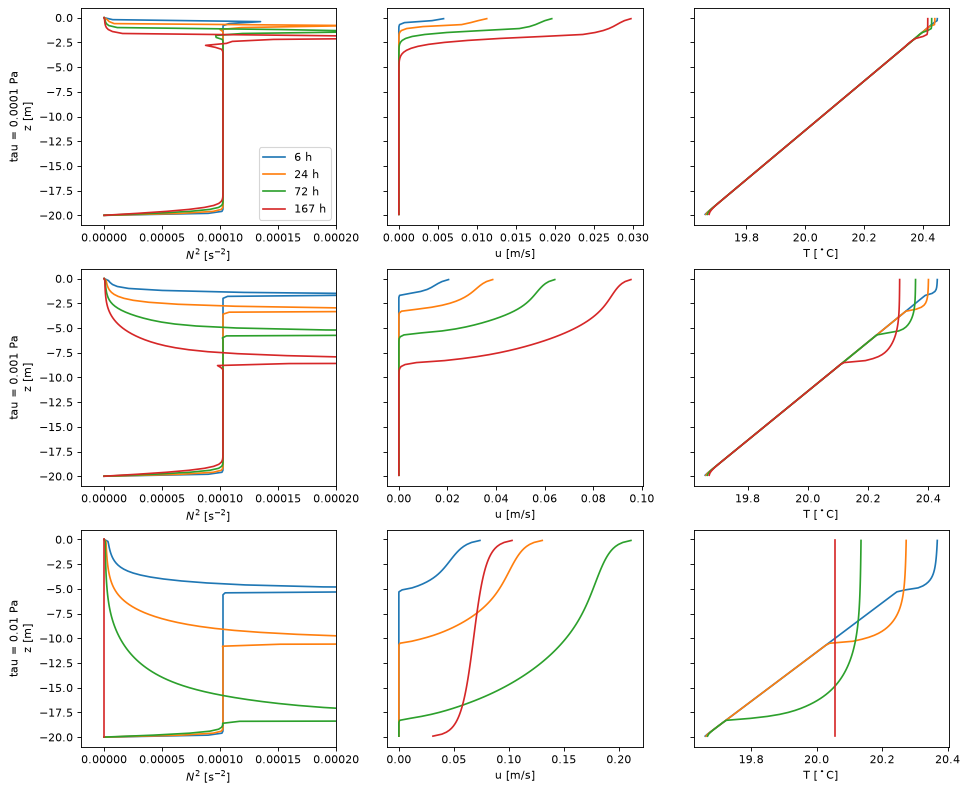

In [3]:
fig, axs = plt.subplots(3, 3, figsize=(14, 12), sharey=True)
hours_list = [6, 24, 72, 167]
for row, tau in enumerate(stresses):
    ds = runs[tau]
    for hours in hours_list:
        sel = ds.sel(time=ds.time[0] + np.timedelta64(hours, 'h'))
        axs[row, 0].plot(sel.NN, sel.zi, label=f'{hours} h')
        axs[row, 1].plot(sel.u, sel.z)
        axs[row, 2].plot(sel.temp, sel.z)
    for col, lab in enumerate(['$N^2$ [s$^{-2}$]', 'u [m/s]', 'T [$^\circ$C]']):
        axs[row, col].set_xlabel(lab)
    axs[row, 0].set_ylabel(f'tau = {tau} Pa\nz [m]')
    axs[row, 0].set_xlim(-0.2 * N2, 2 * N2)
axs[0, 0].legend();

The mixed-layer depth against time, compared with the scaling. The scaling has no prefactor; find one from the model.

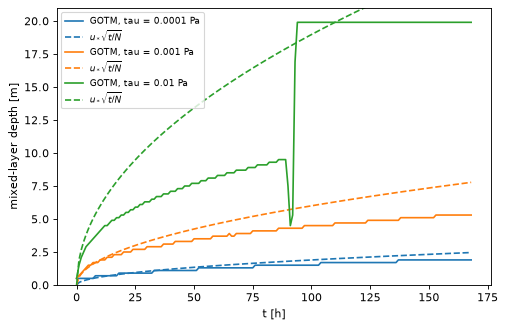

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for tau, color in zip(stresses, ['C0', 'C1', 'C2']):
    ds = runs[tau]
    mld = analysis.mixed_layer_depth(ds, 'temp', threshold=0.01)
    ax.plot(ds.hours, mld, color=color, label=f'GOTM, tau = {tau} Pa')
    ax.plot(ds.hours, analysis.wind_mixed_depth(ds.seconds.values, tau, N2), '--', color=color, label=r'$u_* \sqrt{t/N}$')
ax.set_xlabel('t [h]'); ax.set_ylabel('mixed-layer depth [m]'); ax.set_ylim(0, 21); ax.legend(fontsize=8);

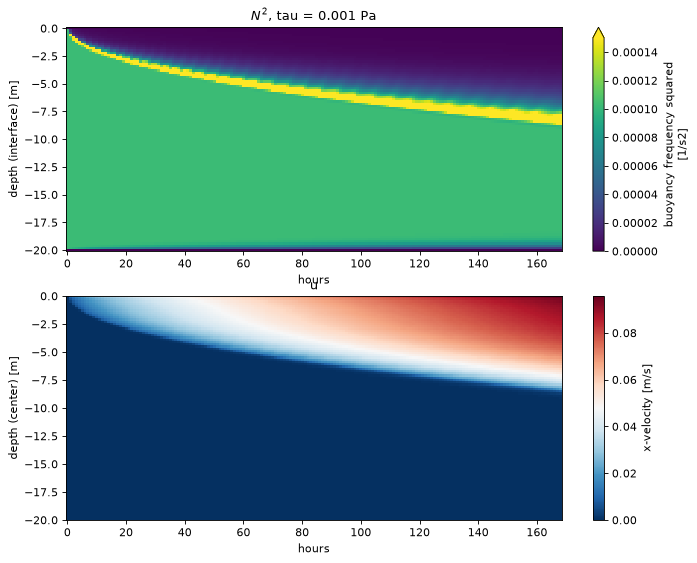

In [5]:
# the whole field for one of the runs
ds = runs[1e-3]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ds.NN.plot(ax=ax1, x='hours', y='zi', vmin=0, vmax=1.5 * N2, cmap='viridis')
ds.u.plot(ax=ax2, x='hours', y='z', cmap='RdBu_r')
ax1.set_title('$N^2$, tau = 0.001 Pa'); ax2.set_title('u');

## (b) Wind together with heating or cooling

Add a surface heat flux of $+500$ W/m$^2$ (warming) and of $-500$ W/m$^2$ (cooling) to the run with $\tau_x = 10^{-3}$ Pa, and compare with the wind-only run.

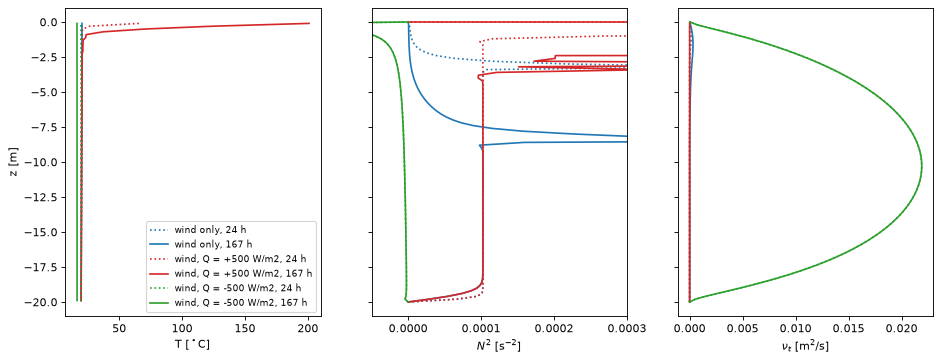

In [6]:
tau = 1e-3
cases = {'wind only': runs[tau]}
for Q in [500, -500]:
    cases[f'wind, Q = {Q:+d} W/m2'] = efmgotm.run('lake', {'temperature.NN': N2, 'surface.fluxes.tx.constant_value': tau,
                                                          'surface.fluxes.heat.constant_value': Q}, workdir=RUNS)
fig, axs = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for (label, ds), color in zip(cases.items(), ['C0', 'C3', 'C2']):
    for hours, ls in [(24, ':'), (167, '-')]:
        sel = ds.sel(time=ds.time[0] + np.timedelta64(hours, 'h'))
        axs[0].plot(sel.temp, sel.z, ls, color=color, label=f'{label}, {hours} h')
        axs[1].plot(sel.NN, sel.zi, ls, color=color)
        axs[2].plot(sel.num, sel.zi, ls, color=color)
axs[0].set_xlabel('T [$^\circ$C]'); axs[0].set_ylabel('z [m]'); axs[0].legend(fontsize=8)
axs[1].set_xlabel('$N^2$ [s$^{-2}$]'); axs[1].set_xlim(-0.5 * N2, 3 * N2)
axs[2].set_xlabel(r'$\nu_t$ [m$^2$/s]');